In [40]:
import igl
import meshplot as mp
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

In [41]:
def make_beam_mesh(width, height, shape):
    x0 = -width/2.0
    y0 = -height/2.0
    I  = shape[0]
    J  = shape[1]
    dx = width/float(I)
    dy = height/float(J)
    V = np.zeros(((I+1)*(J+1),2),dtype=np.float64)
    for j in range(J+1):
        for i in range(I+1):
            k = i + j*(I+1)
            V[k,0] = x0 + i*dx
            V[k,1] = y0 + j*dy
    T = np.zeros((2*I*J,3),dtype=np.int32)
    for j in range(J):
        for i in range(I):
            k00 = (i  ) + (j  )*(I+1)
            k01 = (i+1) + (j  )*(I+1)
            k10 = (i  ) + (j+1)*(I+1)
            k11 = (i+1) + (j+1)*(I+1)
            e = 2*(i + j*I)
            if (i+j)%2:
                T[e,  :] = (k00,k01,k11)
                T[e+1,:] = (k00,k11,k10)
            else:
                T[e,  :] = (k10,k00,k01)
                T[e+1,:] = (k10,k01,k11)                    
    return V, T

V, T = make_beam_mesh(6.0,2.0,(12,6))


def compute_triangle_areas(V,T):
    E = len(T) # Total number of triangles in the mesh
    A = np.zeros((E,),dtype=np.float64)
    for e in range(E):
        # Get triangle indices
        i = T[e,0]
        j = T[e,1]
        k = T[e,2]
        # Get triangle coordinates
        xi = V[i,0]
        xj = V[j,0]
        xk = V[k,0]
        yi = V[i,1]
        yj = V[j,1]
        yk = V[k,1]    
        
        dx1 = xk - xj
        dy1 = yk - yj
        dx2 = xi - xj
        dy2 = yi - yj

        A[e] =  (dx1*dy2 - dx2*dy1 ) / 2.0
    return A

A = compute_triangle_areas(V,T)



N = len(V) # Total number of nodes in the mesh
E = len(T) # Total number of triangles in the mesh

Ke = np.zeros((6,E*6), dtype=np.float64)
Be = np.zeros((E, 3, 6), dtype=np.float64)
K  = np.zeros( (N*2,N*2), dtype=np.float64)
# Compute the D (elasticity) matrix
#
# http://en.wikipedia.org/wiki/Young%27s_modulus
# http://en.wikipedia.org/wiki/Poisson%27s_ratio
#
# This is aluminium like parameters
Ey  = 69e9  # Young modulus
nu = 0.3    # Poisson ration

# TODO - Compute the D (elasticity) matrix
D  = Ey/(1 - nu**2)*np.array([
    [1, nu, 0],
    [nu, 1, 0],
    [0, 0, (1 - nu)/2]
])

# Now compute element stiffness matrices
for e in range(E):
    # Get triangle indices
    i = T[e,0]  
    j = T[e,1]  
    k = T[e,2]  
    # Get triangle coordinates
    xi = V[i,0]
    xj = V[j,0]
    xk = V[k,0]
    yi = V[i,1]
    yj = V[j,1]
    yk = V[k,1]
    # TODO - Compute spatial gradients of the barycentric coordinates
    local_area = A[e]
    diff_ix = -(yk - yj)/local_area/2
    diff_iy = (xk - xj)/local_area/2
    
    diff_jx = -(yi - yk)/local_area/2
    diff_jy = (xi - xk)/local_area/2

    diff_kx = -(yj - yi)/local_area/2
    diff_ky = (xj - xi)/local_area/2
    # TODO - Compute the B matrix
    B1 = np.array([[diff_ix, 0], [0, diff_iy], [diff_iy, diff_ix]])
    B2 = np.array([[diff_jx, 0], [0, diff_jy], [diff_jy, diff_jx]])
    B3 = np.array([[diff_kx, 0], [0, diff_ky], [diff_ky, diff_kx]])
    B = np.block([B1, B2, B3])
    Be[e, :, :] = B
    # TODO - Compute element stiffness matrix and store it in Ke array
    Ke[:, 6*e:6*e+6] = local_area*(B.T@(D@B))


Be = np.array(Be)
print(Be.shape)



# Now do assembly process of global stiffness matrix
for e in range(E):
    # Get global triangle vertex indices
    i = T[e,0]  
    j = T[e,1]  
    k = T[e,2]    
    # Local order of vertex coordinates is i_x, i_y, j_x j_y, k_x, and  k_y. 
    # This is how local vertex indices (0,1,2,..,5) are mapped to global vertex
    # indices
    gidx = [ i, N + i, j,  N + j,  k, N + k]
    # Now we can add the element stiffness matrix to the global matrix using
    # our local-global vertex index mapping.
    
    # TODO - assemble Ke into global K matrix
    Ke_curr = Ke[:, 6*e:6*e + 6]
    for a in range(len(gidx)):
        for b in range(len(gidx)):
            K[gidx[a], gidx[b]] += Ke_curr[a, b]         



def gather_stress(factor=1):
    factor
    load = -10e7*factor
    f = np.zeros((2*N,),dtype=np.float64)
    indices = np.array(np.where(V[:,0]>2.9),dtype=np.uint).flatten() + N
    f[indices] = load
    xindices = np.array(np.where( V[:,0] < -2.9), dtype=np.uint).flatten()
    yindices = xindices + N

    indices = np.hstack((xindices, yindices))
    values  = np.zeros(indices.shape,dtype=np.float64)

    F = np.setdiff1d(np.arange(2*N), indices)

    for i in range(len(indices)):
        index = indices[i]
        value = values[i]  
    
        # TODO - add boundary conditions here
        K[index, :] = 0
        K[:, index] = 0
        K[index, index] = 1
        f[index] = value
        u = np.zeros(f.shape, dtype=np.float64)
    u[indices] = values
    KFF = K[F,:][:,F]
    fF  = f[F]
    u[F] = np.linalg.solve(KFF, fF)       


    # Stress tensor
    triangle_stress = np.zeros((E, 3))  # 3 components per triangle (sigma_xx, sigma_yy, sigma_xy)
    for e in range(E):
        nodes = T[e]
        # Local displacement vector for current triangle
        u_e = np.array([
            u[nodes[0]], u[nodes[0] + N],
            u[nodes[1]], u[nodes[1] + N],
            u[nodes[2]], u[nodes[2] + N]
        ])
        # Get the B matrix for this triangle
        B = Be[e]
        # Compute straink
        strain = B @ u_e
        # Compute stress
        stress = D @ strain
        triangle_stress[e] = stress  # Store the stress vector for this triangle

    # print(triangle_stress.shape)  # Should be (E, 3) 


    V_deformed = np.zeros_like(V)
    V_deformed[:, 0] = V[:, 0] + u[0:N]
    V_deformed[:, 1] = V[:, 1] + u[N:2*N]

    # Compute von Mises stress for each triangle
    sigma_xx = triangle_stress[:, 0]
    sigma_yy = triangle_stress[:, 1]
    sigma_xy = triangle_stress[:, 2]
    von_mises = np.sqrt(sigma_xx**2 - sigma_xx*sigma_yy + sigma_yy**2 + 3*sigma_xy**2)


    # fig = plt.figure()
    # plt.triplot(V[:,0],V[:,1],T)
    # plt.triplot(V_deformed[:, 0], V_deformed[:, 1],T)
    # plt.show()

    return von_mises

factors = np.linspace(0.1, 5.0, 50)
von_mises = []
for factor in factors:
    von_mises.append(gather_stress(factor))


von_mises = np.array(von_mises)


x = 10e1*factors

print(x)



(144, 3, 6)
[ 10.  20.  30.  40.  50.  60.  70.  80.  90. 100. 110. 120. 130. 140.
 150. 160. 170. 180. 190. 200. 210. 220. 230. 240. 250. 260. 270. 280.
 290. 300. 310. 320. 330. 340. 350. 360. 370. 380. 390. 400. 410. 420.
 430. 440. 450. 460. 470. 480. 490. 500.]


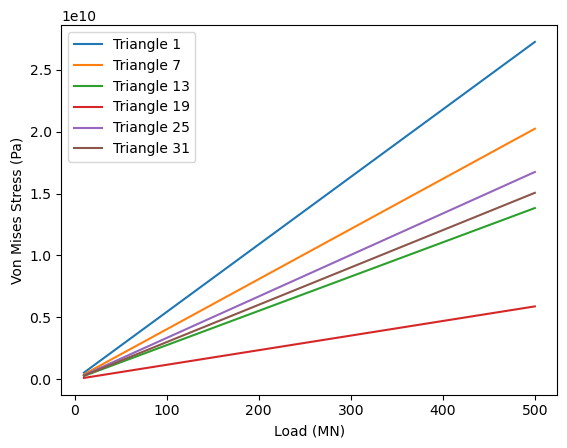

In [ ]:
max_von_mises = np.max(von_mises, 1)
print(max_von_mises.shape)
max_von_mises

(50,)


array([5.44674326e+08, 1.08934865e+09, 1.63402298e+09, 2.17869730e+09,
       2.72337163e+09, 3.26804595e+09, 3.81272028e+09, 4.35739461e+09,
       4.90206893e+09, 5.44674326e+09, 5.99141758e+09, 6.53609191e+09,
       7.08076623e+09, 7.62544056e+09, 8.17011488e+09, 8.71478921e+09,
       9.25946354e+09, 9.80413786e+09, 1.03488122e+10, 1.08934865e+10,
       1.14381608e+10, 1.19828352e+10, 1.25275095e+10, 1.30721838e+10,
       1.36168581e+10, 1.41615325e+10, 1.47062068e+10, 1.52508811e+10,
       1.57955554e+10, 1.63402298e+10, 1.68849041e+10, 1.74295784e+10,
       1.79742527e+10, 1.85189271e+10, 1.90636014e+10, 1.96082757e+10,
       2.01529500e+10, 2.06976244e+10, 2.12422987e+10, 2.17869730e+10,
       2.23316474e+10, 2.28763217e+10, 2.34209960e+10, 2.39656703e+10,
       2.45103447e+10, 2.50550190e+10, 2.55996933e+10, 2.61443676e+10,
       2.66890420e+10, 2.72337163e+10])